<a href="https://colab.research.google.com/github/mishrasatyam9720-debug/Breast-Cancer-Prediction/blob/main/breast_cancer_tensorflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

In [3]:
# set seeds for reproducible results
np.random.seed(42)
tf.random.set_seed(42)

# configurations
pd.set_option('display.max_columns', None)  # show all columns, don't truncate
pd.set_option('display.float_format', lambda x: f'{x:.4f}')  # no scientific notation, 4 decimals
np.set_printoptions(suppress=True)  # no scientific notation for numpy arrays

In [4]:
df = pd.read_csv("/content/breast_cancer_data.csv")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [6]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [7]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,NaN
1,842517,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,NaN
2,84300903,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,NaN
3,84348301,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,NaN
4,84358402,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,NaN


In [8]:
df = df.drop(columns=["id", "Unnamed: 32"])

In [9]:
df["diagnosis"] = df["diagnosis"].replace({"M": 1, "B": 0}).astype(int)

/tmp/ipykernel_575/497367897.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["diagnosis"] = df["diagnosis"].replace({"M": 1, "B": 0}).astype(int)


<Axes: xlabel='diagnosis'>

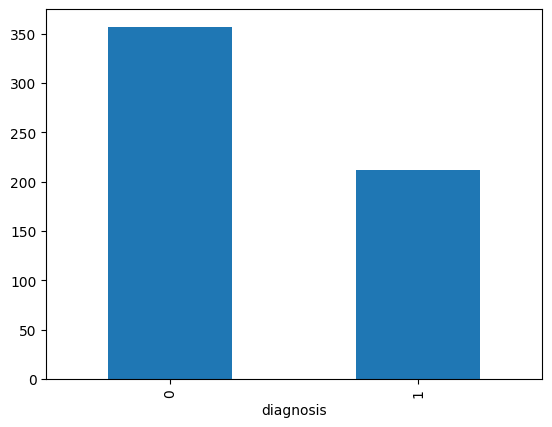

In [10]:
df['diagnosis'].value_counts().plot(kind='bar')

In [11]:
df[["radius_mean","area_mean","smoothness_mean"]].describe()

,radius_mean,area_mean,smoothness_mean
count,569.0000,569.0000,569.0000
mean,14.1273,654.8891,0.0964
std,3.5240,351.9141,0.0141
min,6.9810,143.5000,0.0526
25%,11.7000,420.3000,0.0864
50%,13.3700,551.1000,0.0959
75%,15.7800,782.7000,0.1053
max,28.1100,2501.0000,0.1634


In [12]:
# train/test/val-------
x = df.drop(columns="diagnosis")
y=df["diagnosis"]

In [13]:
x_temp, x_test, y_temp, y_test = train_test_split(x, y, stratify=y, test_size=0.2, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, stratify=y_temp, test_size=0.25, random_state=42)

In [14]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [15]:
model = keras.Sequential([
    keras.Input(shape=(x_train.shape[1],)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
#compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [17]:
# arly stopping val_loss ko dekhta hai, agar 10 epochs tak improve na ho to training rok deta hai aur best wale weights wapas le aata hai. Ye overfitting se bachata hai.
early_stop = keras.callbacks.EarlyStopping(
  monitor="val_loss", patience=10, restore_best_weights=True
)

In [18]:
class PrintEvery10(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs):
        if (epoch + 1) % 10 == 0:
            print(f"epoch {epoch+1:3d} loss {logs['loss']:.4f} acc {logs['accuracy']:.4f} val_loss {logs['val_loss']:.4f} val_acc {logs['val_accuracy']:.4f}")

In [19]:
history=model.fit(
    x_train,y_train,
    validation_data=(x_val,y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, PrintEvery10()],
    verbose=0
)


epoch  10 loss 0.2564 acc 0.9238 val_loss 0.2661 val_acc 0.9123
epoch  20 loss 0.1101 acc 0.9765 val_loss 0.1247 val_acc 0.9561
epoch  30 loss 0.0768 acc 0.9824 val_loss 0.0973 val_acc 0.9474
epoch  40 loss 0.0613 acc 0.9853 val_loss 0.0878 val_acc 0.9649
epoch  50 loss 0.0512 acc 0.9853 val_loss 0.0840 val_acc 0.9649
epoch  60 loss 0.0431 acc 0.9883 val_loss 0.0838 val_acc 0.9737


In [20]:
print("trained_for",len(history.history["loss"]))

trained_for 64


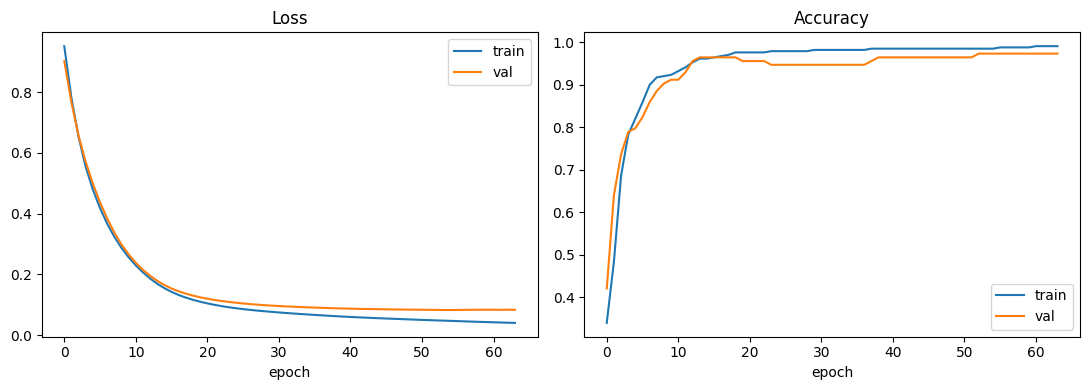

In [21]:
hist = history.history

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(hist["loss"], label="train")
plt.plot(hist["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist["accuracy"], label="train")
plt.plot(hist["val_accuracy"], label="val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()

plt.tight_layout()
plt.show()

In [23]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", round(test_loss, 3))
print("Test accuracy:", round(test_acc, 3))

Test loss: 0.095
Test accuracy: 0.956


In [24]:
y_prob = model.predict(x_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("First 5 probabilities:", y_prob[:5].round(3))
print("First 5 predictions:  ", y_pred[:5])

First 5 probabilities: [0.    1.    0.178 0.821 0.732]
First 5 predictions:   [0 1 0 1 1]


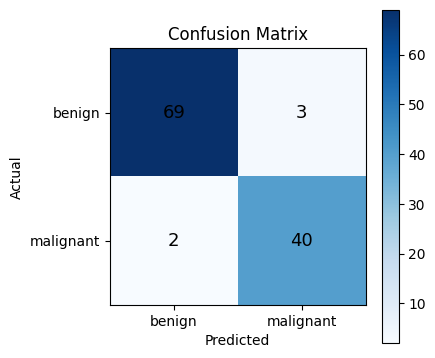

In [25]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(4.5, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks([0, 1], ["benign", "malignant"])
plt.yticks([0, 1], ["benign", "malignant"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
plt.colorbar()
plt.tight_layout()
plt.show()

In [27]:
print(classification_report(y_test, y_pred, target_names=["benign", "malignant"]))

              precision    recall  f1-score   support

      benign       0.97      0.96      0.97        72
   malignant       0.93      0.95      0.94        42

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



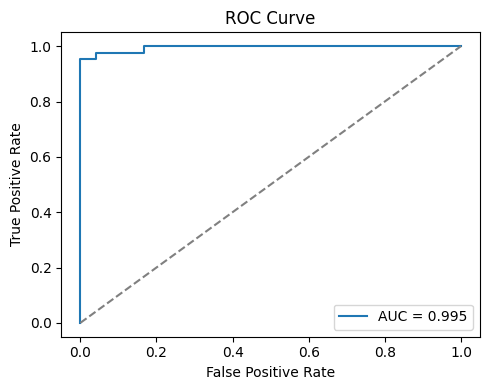

In [28]:
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.tight_layout()
plt.show()

In [29]:
import joblib

# save the model
model.save("breast_cancer_model.keras")

# saving the scaler
joblib.dump(scaler, "scaler.joblib")

print("Saved: breast_cancer_model.keras, scaler.joblib")

Saved: breast_cancer_model.keras, scaler.joblib
